In [1]:
%pip install scikit-learn numpy pandas matplotlib

In [2]:
  import pandas as pd
  import numpy as np
  import matplotlib.pyplot as plt
  print("It works!")

It works!


In [12]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

print(df)
# df.to_csv('student_data.csv', index=False)
df.to_csv('student_data.csv', index=False)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


In [5]:
#Part A
#A1: I decided to remove the 50-hour row because it is a data-entry error and makes a noice

In [13]:
print(df.isna().sum())
print(df.describe().round(2))
# Keep the original to compare 
df_raw = df.copy()

df = df.drop(index=[98, 99])   # impossible attendance (-10) and the 50-hour outlier
df = df.dropna()               # rows 0-5 with missing study_hours
print(df.shape)

study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64
       study_hours  attendance  previous_mark  final_score
count        94.00      100.00         100.00       100.00
mean          5.22       84.27          70.97        42.69
std           5.01       13.48          16.26         6.09
min          -0.24      -10.00          21.38        29.16
25%           3.73       76.83          60.17        38.19
50%           4.81       85.84          71.47        42.76
75%           5.74       90.38          80.57        46.69
max          50.00      112.20         127.79        57.17
(92, 4)


In [10]:
#Part A2
#Feature matrix \(X\): (99, 3) — 99 students and 3 input features.
#Target \(y\): (99,) — one final score for each student.
#Numerical columns: study_hours, attendance, previous_mark, and final_score.
#Target variable: final_score.

In [14]:
X = df[['study_hours', 'attendance', 'previous_mark']]
y = df['final_score']
print("Feature matrix shape:", X.shape)
print(df.dtypes)

Feature matrix shape: (92, 3)
study_hours      float64
attendance       float64
previous_mark    float64
final_score      float64
dtype: object


In [15]:
#Part B1
#Calculate mean, median, and standard deviation

In [16]:
summary = pd.DataFrame({
    'mean': df.mean(),
    'median': df.median(),
    'std': df.std()
}).round(2)
summary

,mean,median,std
study_hours,4.73,4.70,1.85
attendance,85.66,86.74,9.68
previous_mark,70.70,71.01,16.50
final_score,42.72,42.76,6.20


In [17]:
#part B2
#1,Study hours: The typical student studies around 5 hours, while the standard deviation indicates how much study time varies between students.
#2,Attendance: Attendance is generally around 85%, but the standard deviation shows that some students attend more consistently than others.
#3,Previous marks and final scores: Previous marks and final scores vary across students, meaning students do not all have the same academic performance.

In [18]:
#part C, Visualize
#C1. Create a histogram of final_score

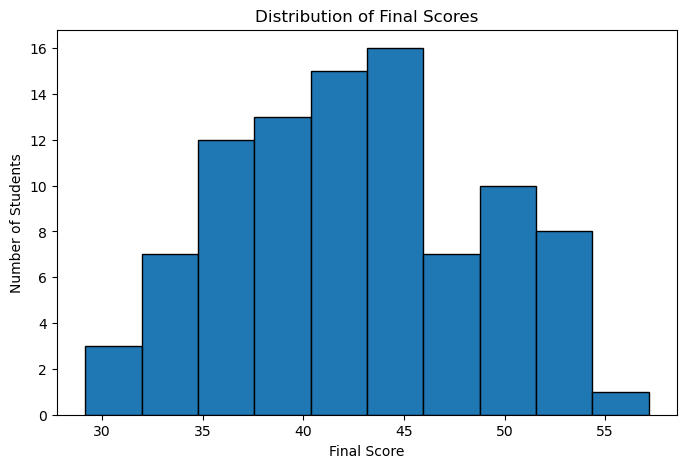

In [19]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df['final_score'], bins=10, edgecolor='black')
plt.title('Distribution of Final Scores')
plt.xlabel('Final Score')
plt.ylabel('Number of Students')
plt.show()


In [20]:
#C2. Scatter plot of study hours vs. final score

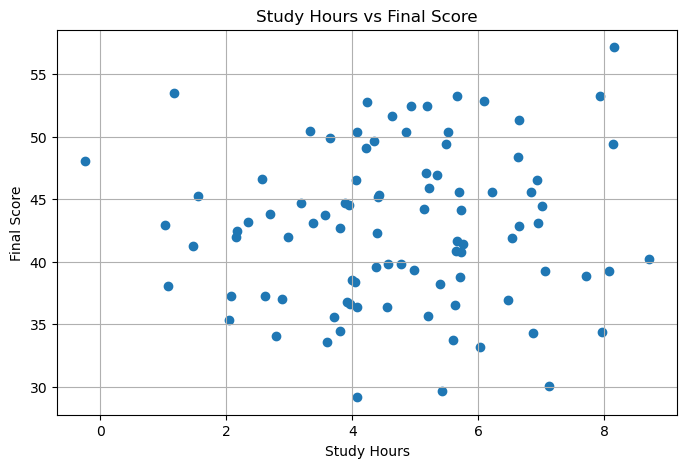

In [21]:

plt.figure(figsize=(8, 5))
plt.scatter(df['study_hours'], df['final_score'])
plt.title('Study Hours vs Final Score')
plt.xlabel('Study Hours')
plt.ylabel('Final Score')
plt.grid(True)
plt.show()


In [22]:
#part c
# 1, If the dots generally rise from left to right, the relationship is positive.
#2,If they generally fall from left to right, the relationship is negative.
#3,If they are scattered without a clear pattern, the relationship is weak.

In [24]:
#Part D — Correlation and Causality
#D1. Calculate the Pearson correlation coefficient

correlation = df['study_hours'].corr(df['final_score'])

print("Pearson correlation:", round(correlation, 4))


Pearson correlation: 0.0509


In [25]:
#part D2,
#o. Correlation does not guarantee an individual student's score.
#, A possible confounding variable is prior knowledge or academic ability. A student who already understands the material might need fewer study hours to achieve a high score, while another student might study longer because the material is difficult.

In [26]:
#Part E — Vectors and Dot Product
#E1–E3. Select a student and calculate the prediction

In [27]:

import numpy as np

# Select the first student, excluding the target
x = df[['study_hours', 'attendance', 'previous_mark']].iloc[0].to_numpy()

# Given weights and bias
w = np.array([0.5, 0.2, 0.4])
b = 5

# Calculate dot product and prediction
y_pred = np.dot(w, x) + b

print("Student vector:", x)
print("Weight vector:", w)
print("Dot product:", np.dot(w, x))
print("Predicted score:", y_pred)


Student vector: [  8.15842563 103.86185901  77.72552901]
Weight vector: [0.5 0.2 0.4]
Dot product: 55.94179622118041
Predicted score: 60.94179622118041


In [28]:
#E4. What do the weights and bias represent?
#Weights represent how much each input contributes to the model's prediction, according to the formula.
#1, 0.5 is the weight for study hours.
#2, 0.2 is the weight for attendance.
#3, 0.4 is the weight for previous marks.

In [29]:
#Part F — Scaling
#F1. Standardize study hours and previous marks


In [30]:

# Make a copy so the original columns remain unchanged
df_scaled = df.copy()

columns_to_scale = ['study_hours', 'previous_mark']

for col in columns_to_scale:
    mean = df_scaled[col].mean()
    std = df_scaled[col].std(ddof=0)

    df_scaled[col + '_standardized'] = (
        df_scaled[col] - mean
    ) / std

print(df_scaled[
    ['study_hours', 'study_hours_standardized',
     'previous_mark', 'previous_mark_standardized']
].head())

# Verify the standardized means and standard deviations
print("\nStandardized means:")
print(df_scaled[
    ['study_hours_standardized', 'previous_mark_standardized']
].mean().round(4))

print("\nStandardized standard deviations:")
print(df_scaled[
    ['study_hours_standardized', 'previous_mark_standardized']
].std(ddof=0).round(4))


    study_hours  study_hours_standardized  previous_mark  \
6      8.158426                  1.860029      77.725529   
7      6.534869                  0.978058      77.706789   
8      4.061051                 -0.365804      77.725715   
9      6.085120                  0.733739     127.790972   
10     4.073165                 -0.359224      78.563358   

    previous_mark_standardized  
6                     0.428101  
7                     0.426959  
8                     0.428113  
9                     3.479827  
10                    0.479171  

Standardized means:
study_hours_standardized     -0.0
previous_mark_standardized    0.0
dtype: float64

Standardized standard deviations:
study_hours_standardized      1.0
previous_mark_standardized    1.0
dtype: float64


In [ ]:
#F2. Why does K-Nearest Neighbors need scaling?
#K-Nearest Neighbors (KNN) predicts using the distance between data points. 
#Without scaling, features with larger numerical ranges can dominate the distance calculation.
#Without scaling, KNN may give too much influence to previous_mark because it has a much larger numerical range than study_hours. 
#Standardization places both features on comparable scales so that distance calculations are not dominated simply by the units or magnitude of a feature.